# Final Exam

# Results

## Q1

Analytical solution:

$$f(x)={{x^{\frac{7}{5}}-1}\over{9}}=3\quad\Rightarrow\quad x^{\frac{7}{5}}=28\quad\Rightarrow\quad x^*=28^{\frac{5}{7}}\approx 10.81$$

Let $g(x)=x^{\frac{7}{5}}-28=0$, we're going to find the root of $g(x)$.

Result: $x^*\approx 10.806481347419322$

![Image 1](./Q1.png)


## Q2

We use `numpy.linalg.solve` to get the reference solution $x$ for each random $b$ and record the mean time and mean residual error.

As is not stated in the question, we use $\mathbf{1}_n$ as the initial iteration value.

The result is shown below:

```
Average time:
 dict_items([('Gauss', 0.036021543997339915), ('LU', 0.01835329200839624), ('Jacobi', 0.0023594440007582308), ('Seidel', 0.004088455999735742)])
Average error:
 dict_items([('Gauss', 6.628227704530011e-16), ('LU', 6.704278143013306e-16), ('Jacobi', 7.41849544489407e-10), ('Seidel', 2.6611738999009675e-10)])
```

| Method | Average Time (s) | Average Residual Error |
| :----: | :--------------: | :-------------------------------------: |
| Gauss Elimination | 0.0360 | $6.6282\times 10^{-16}$ |
| LU Decomposition  | 0.0184 | $6.7043\times 10^{-16}$ |
| Jacobi Method     | 0.0024 | $7.4185\times 10^{-10}$ |
| Gauss-Seidel      | 0.0041 | $2.6612\times 10^{-10}$ |

**Table 2: Information of different methods to solve linear equation** 

## Q3

We can use inverse power method to get the eigen of the smallest absolute value. Since given a matrix $A$, if $\lambda_0\in\lambda(A)$ then $\exists v_0$ such that $Av_0=\lambda_0 v_0$, followed by $(A-I)v_0=(\lambda_0 - 1)v_0$, $\lambda_0 - 1\in\lambda(A- I)$.

Thus to find the eigenvalues closest to $1$, we can adopt the inverse power method to find the absolutely smallest eigenvalue $\lambda_0$ of $A - I$, then the result should be $\lambda_0 + 1$.

**Result:**

![EigvecError](./Q3.a.png)

**Figure 3: Eigenvector errors $||Ax_n-\lambda_n x_n||_2$**

![EigvalError](./Q3.b.png)

**Figure 4: Eigenvalue difference $|\lambda_n-1|$**


## Q4

Let $f(x_1,x_2) = (f_1(x_1,x_2), f_2(x_1, x_2))=(x_1-x_1^2+4x_2-12, (x_1-2)^2+(2x_2-3)^2-25)$, then the solutions of the nonlinear equations are the zero points of $f$ as well.

By transforming the equations into 

$x_2=\dfrac{12-x_1+x_1^2}{4},\quad x_1 = \pm\sqrt{25 - (2x_2-3)^2}+2$

we can draw the equations as below:

![Equation](./Q4.d.png)

**Figure 5: Plot of the equations**

Use `scipy`'s `optimize.fsolve` method, we can find the 2 solutions of the equations: $(-1, 3.5)$ and $(2.5469, 3.985)$.

For the Newton's method, the iteration formula is $f(X_{n+1}) = X_n - J^{-1}(X_n)f(X_n)$, where 

$$
J(X_n)=\begin{bmatrix}\dfrac{\partial f_1}{\partial x_1}&\dfrac{\partial f_1}{\partial x_2}\\
\dfrac{\partial f_2}{\partial x_1}&\dfrac{\partial f_2}{\partial x_2}\end{bmatrix}=
\begin{bmatrix}
1-2x_1&4\\2(x_1-2)&4(2x_2-3)
\end{bmatrix}
$$

is the jacobi matrix at $X_n$ and its inverse is

$$
J(X_n)^{-1}=
\begin{bmatrix}
-12+8x_2&4-2x_1\\-4&1-2x_1
\end{bmatrix}
$$

![Path](./Q4.a.png)

**Figure 6: Path of the iteration points**

![Error1](./Q4.b.png)

**Figure 7: Errors during the iteration**

![Error2](./Q4.c.png)

**Figure 8: Errors during the iteration (log-log plot)**

## Q5

The steepest descent method uses gradient direction as the proceeding direction. For multivariate equations $F(X)=0$, the evaluation function is half of the 2-norm for convenience: $g(X) = \dfrac{1}{2}F(X)^TF(X)$. Hence the gradient direction and the iteration formula is 

$$J_g(X) = J(X)^TF(X),\quad X_{n+1}=X_n - \alpha J(X_n)^TF(X_n)$$

where $\alpha$ is the stepsize. The simplest way is to let $\alpha$ be a constant, here we choose $0.0075$. As we can predict, the process may oscillate or explode, and even the proceeding direction is directly towards the solution, it may go away from it since the stepsize is fixed.

To resolve this, one method is to find a flexible stepsize, for example, a quadratic approximation of $F$:

$$F(X) = F(X_0) + J_F(X_0)(X-X_0) + \dfrac{1}{2}H_F(X_0)(X-X_0)^2+o(||X-X_0||^2)$$

Using the best stepsize for quadratic equations, i.e. 

$$\alpha=\mathrm{argmin}_\alpha{||F(X_n)-\alpha J(X_n)^TF(X_n)||}$$

we have $\alpha_i = \dfrac{J_{f_i}^TJ_{f_i}}{J_{f_i}^TH_{f_i}J_{f_i}}$, $i\in\{1,2\}$.

Since the target function has local minimal, we can not alway get a solution, when such occasion is met, we should perturb the initial value to a better place. By using adaptive stepsize, the method should perform better,

For initial value $(0,0)$, the following figures should that neither fixed stepsize steepest decent method nor adaptive stepsize gives a solution, they converge to a local minimum.

![fixed1.1](./Q5.fixed.a.png)

**Figure 9: Converge path given a fixed step size starting from $(0,0)$**

![fixed1.2](./Q5.fixed.b.png)
![fixed1.3](./Q5.fixed.c.png)

**Figure 10: Errors given a fixed step size starting from $(0,0)$**

![dynamic1.1](./Q5.dynamic.a.png)

**Figure 11: Converge path given an adaptive step size starting from $(0,0)$**

![dynamic1.2](./Q5.dynamic.b.png)
![dynamic1.3](./Q5.dynamic.c.png)

**Figure 12: Errors given an adaptive step size starting from $(0,0)$**

The following figures shows that if we change the initial value to $(2,2)$, then fixed step size will make the iteration points oscillate near a zerop point while adaptive step size will converge to it.

![fixed2.1](./Q5.fixed2.a.png)

**Figure 13: Converge path given a fixed step size starting from $(2,2)$**

![fixed2.2](./Q5.fixed2.b.png)
![fixed2.3](./Q5.fixed2.c.png)

**Figure 14: Errors given a fixed step size starting from $(2,2)$**

![dynamic2.1](./Q5.dynamic2.a.png)

**Figure 15: Converge path given an adaptive step size starting from $(2,2)$**

![dynamic2.2](./Q5.dynamic2.b.png)
![dynamic2.3](./Q5.dynamic2.c.png)

**Figure 16: Errors given an adaptive step size starting from $(2,2)$**

Therefore, steepest descent method with adaptive step size performs better.

# Collaboration

No collaboration on this project

# Academic Integrity

On my personal integrity as a student and member of the UCD community, I have not given, nor received and unauthorized assistance on this assignment.

# Appendix

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from ttictoc import tic, toc
from tqdm import tqdm
from collections import defaultdict
from scipy.optimize import fsolve

## Q1

In [6]:
def bisection(f, a, b, tol, trace=None):
    while True:
        c = (b + a) / 2
        if trace is not None:
            trace.append(c)
        if np.abs(b - a) < tol:
            return c if f(a) * f(b) <= 0 else None
        if f(a) * f(c) <= 0:
            b = c
        elif f(b) * f(c) <= 0:
            a = c
        else:
            return None

In [10]:
f = lambda x: x ** (7 / 5) - 28
trace = []

bisection(f, 0, 24, 1e-8, trace)

10.806481347419322

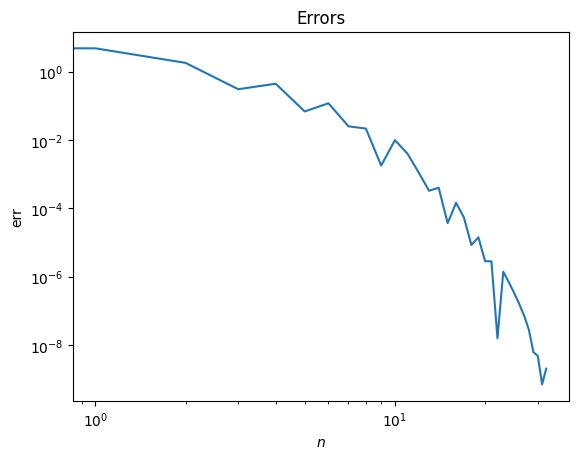

In [12]:
err = np.abs(np.array(trace) - 10.806481345346757)
fig = plt.figure()
plt.plot(err)
plt.xlabel("$n$")
plt.ylabel("err")
plt.xscale("log")
plt.yscale("log")
plt.title("Errors")
plt.savefig("Q1.png", dpi=350)
plt.show()

## Q2

In [24]:
eps = np.finfo(float).eps
def back_substitution(U: np.ndarray, b: np.ndarray) -> np.ndarray | None:
    x = np.zeros_like(b)
    if abs(U[-1, -1]) < eps:
        return None
    x[-1] = b[-1] / U[-1, -1]
    for i in range(len(b), 0, -1):
        x[i - 1] = (b[i - 1] - np.dot(U[i - 1, i:], x[i:])) / U[i - 1, i - 1]
    assert(np.linalg.norm(U @ x - b, 2) < 0.0001) # type: ignore
    return x

def forward_substitution(L: np.ndarray, b: np.ndarray) -> np.ndarray | None:
    x = np.zeros_like(b)
    if abs(L[0, 0]) < eps:
        return None
    x[0] = b[0] / L[0, 0]
    for i in range(1, len(b)):
        x[i] = (b[i] - np.dot(x[:i], L[i,:i])) / L[i][i]
    assert(np.linalg.norm(L @ x - b, 2) < 0.0001) # type: ignore
    return x
def LUdecomposition(A: np.ndarray):
    n = len(A)
    L = np.identity(n)
    U = A.copy()
    for j in range(0, n - 1):
        for i in range(j + 1, n):
            if abs(U[j][j]) < eps:
                return None # without pivoting, we cannot handle this
            m = U[i][j] / U[j][j]
            U[i, :] = U[i, :] - m * U[j, :]
            L[i, j] = m
    assert(np.linalg.norm(L @ U - A, 2) < 0.0001)
    return L, U
def solveLUb(L: np.ndarray, U: np.ndarray, b: np.ndarray) -> np.ndarray | None:
    y = forward_substitution(L, b)
    if y is None:
        return y
    x = back_substitution(U, y)
    return x
def solveLU(A: np.ndarray, b: np.ndarray) -> np.ndarray | None:
    L, U = LUdecomposition(A)
    x = solveLUb(L, U, b)
    return x

In [25]:
def gaussian_elimination(A: np.ndarray, b: np.ndarray):
    n = len(A)
    U = A.copy()
    bp = b.copy()
    for j in range(0, n - 1):
        for i in range(j + 1, n):
            if abs(A[j][j]) < eps:
                return None # without pivoting, we cannot handle this
            m = U[i][j] / U[j][j]
            U[i, :] = U[i, :] - m * U[j, :]
            bp[i] -= m * bp[j]
    return U, bp
def solveGE(A: np.ndarray, b: np.ndarray) -> np.ndarray | None:
    U, bp = gaussian_elimination(A, b)
    assert(np.linalg.norm(np.linalg.solve(A, b) - np.linalg.solve(U, bp), 2) < 0.0001)
    x = back_substitution(U, bp)
    assert(np.linalg.norm(A @ x - b, 2) < 0.0001)
    return x

In [26]:
def jordan(A, b, x0, tol, max_iter, force=False, path=None):
    n = 0
    D = np.diag(A)
    Dinv = np.diag(np.divide(1, D))
    N = np.identity(np.shape(A)[0]) - Dinv @ A
    y = Dinv @ b
    if path is not None:
        path.clear()
        path.append(x0.copy())
    x1 = N @ x0 + y
    if path is not None:
        path.append(x1.copy())
    while (force or np.linalg.norm(x1 - x0) > tol) and n < max_iter:
        x0 = x1[:]
        x1 = N @ x0 + y
        if path is not None:
            path.append(x1.copy())
        if np.linalg.norm(x1) > 1e8:
            return None, None
        n = n + 1
    return x1, n
def gauss_seidel_step(A, b, x, xp=None):
    if xp is None:
        xp = np.array([] * len(x))
    n = np.shape(A)[0]
    for i in range(n):
        xp[i] = (b[i] - np.dot(A[i, :i], xp[:i]) -
            np.dot(A[i, (i+1):], x[(i+1):])) / A[i, i]
    return xp

In [27]:
def gauss_seidel(A, b, x0, tol, max_iter, force=False, path=None):
    if path is not None:
        path.clear()
        path.append(x0.copy())
    n = 0
    x1 = np.zeros_like(x0)
    while n == 0 or (force or np.linalg.norm(x0 - x1) > tol) and n < max_iter:
        if n != 0:
            x0 = x1.copy()
            x1 = gauss_seidel_step(A, b, x0, x1)
        if path is not None:
            path.append(x1.copy())
        if np.linalg.norm(x1) > 1e8:
            return None, None
        n = n + 1
    return x1, n

In [36]:
n = 100
I = np.identity(n)
A = 7 * I + 0.1 * (
    I[np.random.permutation(n), :] + np.random.normal(0, 1, (n, n)))
bs = [np.random.normal(0, 1, (100, )) for _ in range(25)]

In [49]:
ave_time = defaultdict(int)
ave_err = defaultdict(int)
for b in tqdm(bs):
    ref = np.linalg.solve(A, b)

    tic()
    x = solveGE(A, b)
    ave_time['Gauss'] += toc() / len(bs)
    ave_err['Gauss'] += np.linalg.norm(x - ref, 2) / len(bs)

    tic()
    L, U = LUdecomposition(A)
    x = solveLUb(L, U, b) 
    ave_time['LU'] += toc() / len(bs)
    ave_err['LU'] += np.linalg.norm(x - ref, 2) / len(bs)

    tic()
    x, _ = jordan(A, b, np.ones_like(b), 1e-8, 1000)
    ave_time['Jacobi'] += toc() / len(bs)
    ave_err['Jacobi'] += np.linalg.norm(x - ref, 2) / len(bs)

    tic()
    x, n = gauss_seidel(A, b, np.ones_like(b), 1e-8, 1000)
    ave_time['Seidel'] += toc() / len(bs)
    ave_err['Seidel'] += np.linalg.norm(x - ref, 2) / len(bs)

100%|██████████| 25/25 [00:01<00:00, 13.69it/s]


In [54]:
print(f"Average time:\n {ave_time.items()}")
print(f"Average error:\n {ave_err.items()}")

Average time:
 dict_items([('Gauss', 0.036021543997339915), ('LU', 0.01835329200839624), ('Jacobi', 0.0023594440007582308), ('Seidel', 0.004088455999735742)])
Average error:
 dict_items([('Gauss', 6.628227704530011e-16), ('LU', 6.704278143013306e-16), ('Jacobi', 7.41849544489407e-10), ('Seidel', 2.6611738999009675e-10)])


In [55]:
n = 100
R = 0.5 * np.random.random((n, n))
B = R + R.T
A = B + np.diag(np.array([-4] * 100))
Am = A - np.diag(np.array([1] * 100))

In [56]:
def power(A, x0, tol=1e-8, max_iter=1000, collect=False):
    x1 = np.ones_like(x0)
    x1 = x1 * np.inf
    i = 0
    lams = []
    points = [x0]
    while np.linalg.norm(x1 - x0) > tol and i < max_iter:
        if i > 0:
            x0 = x1
        i += 1
        x1 = A @ x0
        x1 /= np.linalg.norm(x1, 2)
        if collect:
            lams.append(np.dot(x1, A @ x1) / np.dot(x1, x1))
            points.append(x1)
            if len(lams) > 1 and np.abs(lams[-2] - lams[-1]) < tol:
                break
    return np.dot(x1, A @ x1) / np.dot(x1, x1), x1, \
            (lams if collect else None), (points if collect else None), i

def inverse_power(A, x0, mu, tol=1e-8, max_iter=1000, collect=False):
    L, U = LUdecomposition(A - mu * np.identity(len(x0)))
    Ainv = np.zeros_like(A)
    for i in range(len(x0)):
        b = np.zeros_like(x0)
        b[i] = 1
        Ainv[:, i] = solveLUb(L, U, b)
    
    res = power(Ainv, x0, tol, max_iter, collect)
    res = list(res)
    res[0] = 1 / res[0] # type: ignore
    if res[2] is not None:
        res[2] = [1 / m for m in res[2]]  # type: ignore
    return tuple(res)

In [57]:
res = inverse_power(Am, np.ones(n), 0, tol=1e-8, collect=True)
print(f"Eigenvalue: {res[0] + 1}")
print(f"Iterations: {res[4]}")

Eigenvalue: -0.06091587652252639
Iterations: 38


In [59]:
# Ref
eigvals, eigvecs = np.linalg.eig(A)
index = np.argmin(np.abs(eigvals - 1))
closest_eigenvalue = eigvals[index]
closest_eigenvector = eigvecs[:, index]
print(f"Eigenvalue closest to 1: {closest_eigenvalue}")
print(f"Eigenvector: {closest_eigenvector}")

Eigenvalue closest to 1: -0.06091585700753287
Eigenvector: [ 0.00587562  0.20918668 -0.11907005 -0.0474041  -0.04372183  0.06953507
 -0.12330357 -0.05237016 -0.01765198  0.01721396  0.00743426  0.02396507
  0.15111424 -0.04743425 -0.06422685  0.08696527  0.1537856   0.11961852
  0.10975309  0.24675427  0.0109011   0.02643314  0.03329973 -0.17148746
  0.06614133  0.00428484  0.02451417 -0.06190086  0.00675884  0.05108534
  0.03781527 -0.11762638  0.13656847  0.06972529 -0.0543739   0.2533053
 -0.10630908 -0.03738628 -0.01625069 -0.1559565  -0.05774413 -0.07880287
 -0.02627251 -0.14570845  0.11458588 -0.05739628 -0.08618216 -0.04654321
  0.10590348 -0.04290318  0.03453137  0.11367364 -0.03793043 -0.00762721
  0.09248644  0.05885986 -0.0765717   0.1356005  -0.21663937 -0.01982285
  0.13058876  0.05752266  0.19527542 -0.14691996  0.17607219 -0.02101707
 -0.0173585   0.0592241   0.07723941 -0.12335301 -0.01343015  0.03004045
 -0.05714944 -0.05529351  0.00275706  0.15468581  0.15688003 -0.04

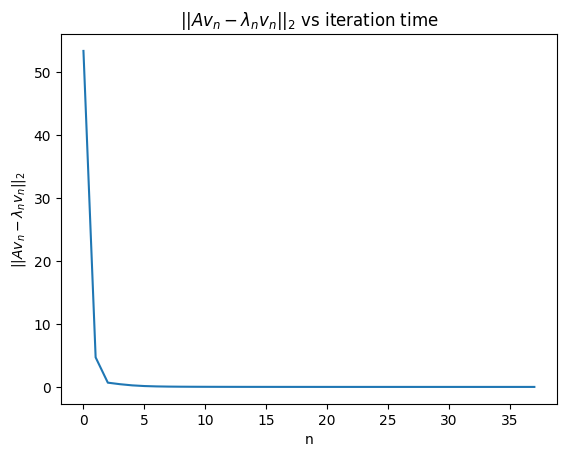

In [60]:
errvecs = [np.linalg.norm(A @ res[3][i + 1] - (res[2][i] + 1) * res[3][i + 1], 2) for i in range(len(res[2]))]

fig = plt.figure()
plt.plot(errvecs)
plt.xlabel("n")
plt.ylabel("$||Av_n - \lambda_n v_n||_2$")
plt.title("$||Av_n - \lambda_n v_n||_2$ vs iteration time")
plt.savefig("Q3.a.png", dpi = 300)
plt.show()

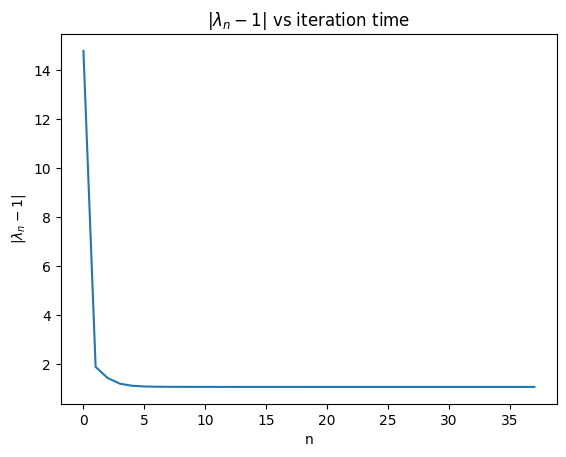

In [61]:
fig = plt.figure()
plt.plot(np.abs(np.array(res[2])))
plt.xlabel("n")
plt.ylabel("$|\lambda_n - 1|$")
plt.title("$|\lambda_n - 1|$ vs iteration time")
plt.savefig("Q3.b.png", dpi = 300)
plt.show()

## Q4

In [62]:
f1 = lambda x: x[0] - x[0] ** 2 + 4 * x[1] - 12
f2 = lambda x: (x[0] - 2) ** 2 + (2 * x[1] - 3) ** 2 - 25

J = lambda x: np.array([[1 - 2 * x[0], 4], [-4 + 2 * x[0], -12 + 8 * x[1]]])
Jdet = lambda x: 4 + 16 * x[0] + 8 * x[1] - 16 * x[1] * x[0]
Jinv = lambda x: np.array([[-12 + 8 * x[1], -4], [4 - 2 * x[0], 1 - 2 * x[0]]]) / Jdet(x)

F = lambda x: np.array([f1(x), f2(x)])
NG = lambda x: x - Jinv(x) @ F(x)

In [63]:
def solve_fixed_point(G, x0, tol, max_iter, log=False, force=False):
    x1 = x0.copy()
    x0 = np.ones_like(x1) * np.inf
    if log:
        logs = [list(x1.copy())]
    i = 0
    while (force or (np.linalg.norm(x1 - x0, 1) > tol)) and i < max_iter:
        x0 = x1
        x1 = G(x0)
        if log:
            logs.append(x1.copy()) # type: ignore
        i += 1
    return x1, i, np.array(logs) if log else None # type: ignore

In [85]:
print(f"Reference Solution 1: {fsolve(F, np.ones((2,)), xtol=1e-10)}")
print(f"Reference Solution 2: {fsolve(F, [2,4], xtol=1e-10)}")

Reference Solution 1: [-1.   3.5]
Reference Solution 2: [2.54694647 3.98499746]


In [70]:
def run(init, func, title, force=False):
      x_init = init
      res, it, logs = solve_fixed_point(func, x_init, 1e-6, 1000, True, force)
      print(f"Initial value: {x_init}")
      print(f"Results: {res}")
      print(f"Iteration: {it}")

      n = 100
      xs = np.linspace(-5, 8, n)
      ys = np.linspace(-5, 8, n)
      X, Y = np.meshgrid(xs, ys)
      Z = [[np.sqrt(f1([X[i, j], Y[i, j]])**2 + f2([X[i, j], Y[i, j]]) ** 2) 
            for i in range(n)] for j in range(n)]
      levels = np.linspace(np.min(Z), np.max(Z), 128)

      plt.figure()
      plt.contourf(Y, X, Z, levels=levels)
      plt.colorbar()
      plt.title(f"Norm of $F(X)$, start from {init}")
      plt.xlabel("$x_1$")
      plt.ylabel("$x_2$")

      xp1 = np.array([-1, 3.5])
      xp2 = np.array([2.54695, 3.985])

      plt.scatter([xp1[0], xp2[0]], [xp1[1], xp2[1]], label="Zero points", color="purple")

      plt.plot(logs[:, 0], logs[:, 1], label="Newton's method", color='orange')
      plt.xlim([-5, 5])
      plt.ylim([-5, 8])

      plt.legend()
      plt.savefig(f"{title}.a.png", dpi=450)
      plt.show()

      errs = [min(
            np.linalg.norm(np.array(x) - xp1, 2),
            np.linalg.norm(np.array(x) - xp2, 2)
      ) for x in logs]

      plt.figure()
      plt.plot(errs)
      plt.xlabel("n")
      plt.ylabel("$||x_n - x^*||_2$")
      plt.title("Residues (2-norm) vs #iteration")
      plt.savefig(f"{title}.b.png", dpi=300)
      
      plt.xscale("log")
      plt.yscale("log")
      plt.savefig(f"{title}.c.png", dpi=300)
      plt.show()

Initial value: [0 0]
Results: [-1.   3.5]
Iteration: 10


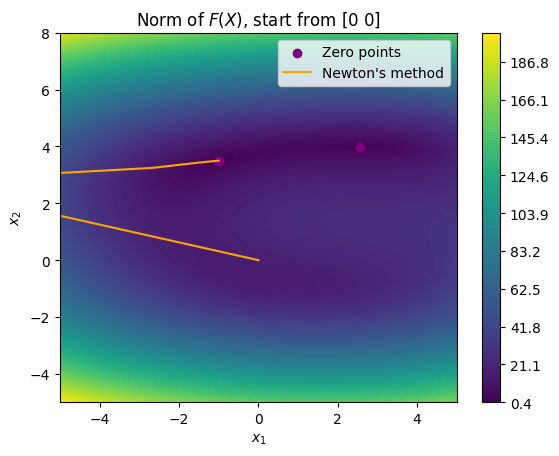

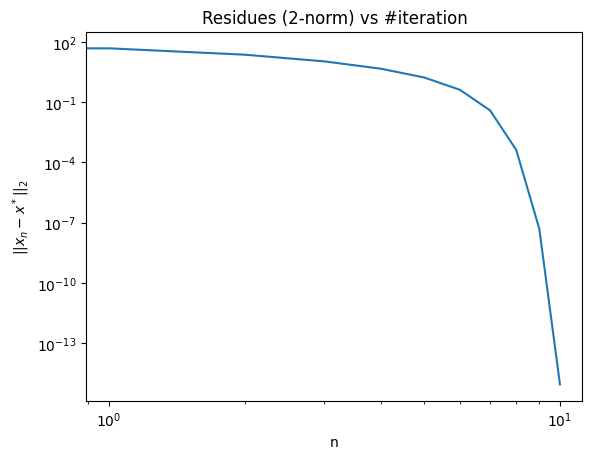

In [71]:
run(np.array([0, 0]), NG, "Q4")

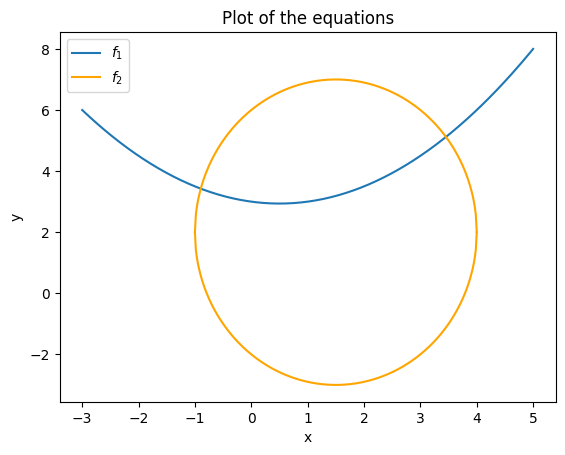

In [78]:
x1s = np.linspace(-3, 5, 300)
eq1 = lambda x1: (12 - x1 + x1**2) / 4
y1s = eq1(x1s)

x2s = np.linspace(-1, 4, 300)
eq21 = lambda x2: np.sqrt(25 - (2 * x2 - 3) ** 2) + 2
eq22 = lambda x2: -np.sqrt(25 - (2 * x2 - 3) ** 2) + 2
y2s1 = eq21(x2s)
y2s2 = eq22(x2s)

plt.figure()
plt.plot(x1s, y1s, label="$f_1$")
plt.plot(x2s, y2s1, color='orange', label="$f_2$")
plt.plot(x2s, y2s2, color='orange')
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Plot of the equations")
plt.savefig("Q4.d.png", dpi=300)


## Q5

Initial value: [0 0]
Results: [ 0.01674771 -0.25509228]
Iteration: 1000


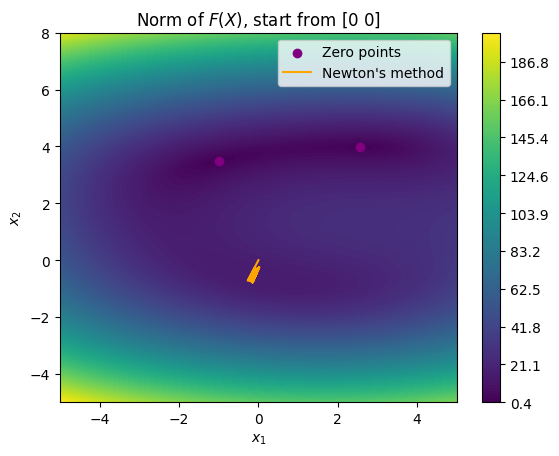

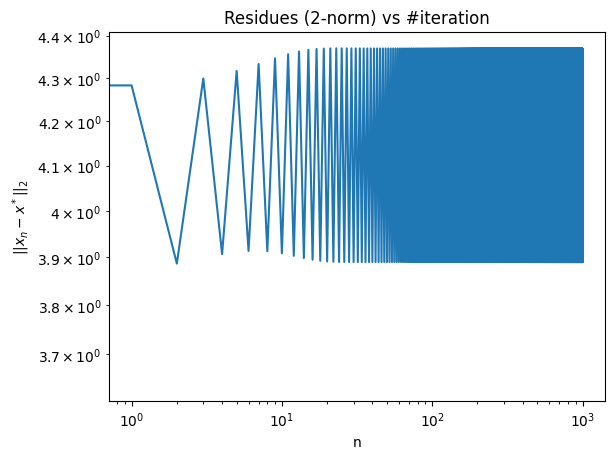

In [87]:
gamma = 0.0075
S1 = lambda x: x - gamma * J(x).T @ F(x)
run(np.array([0, 0]), S1, "Q5.fixed")

Initial value: [0 0]
Results: [ 0.03247667 -0.60419801]
Iteration: 1000


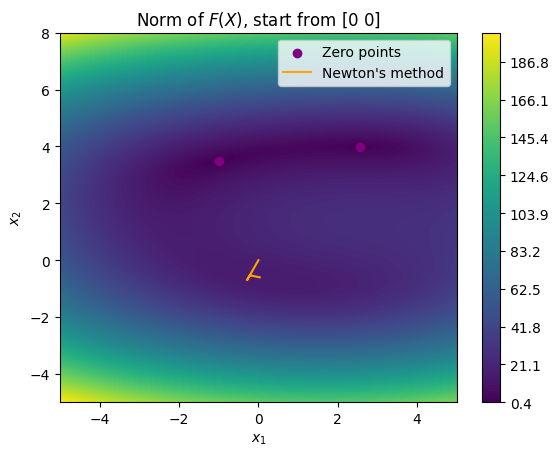

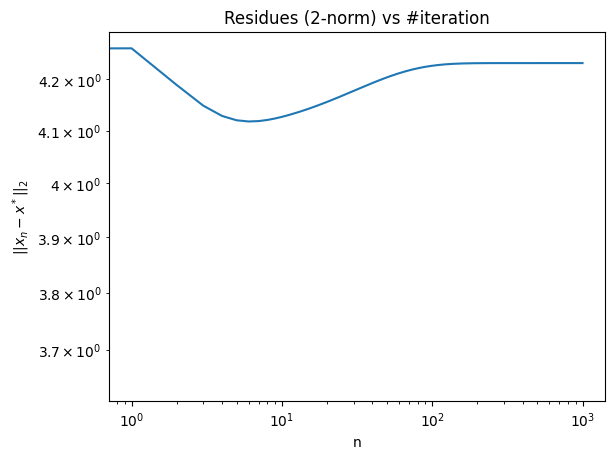

In [95]:
H = lambda x: np.array([
    [
        34 - 60 * x[0] + 24 * x[0] ** 2 - 64 * x[1] + 16 * x[1] ** 2,
        8 * (13 + 4 * x[0] * (x[1] - 2) - 8 * x[1])
    ],
    [
        8 * (13 + 4 * x[0] * (x[1] - 2) - 8 * x[1]),
        16 * (8 - 4 * x[0] + x[0] ** 2 - 36 * x[1] + 12 * x[1] ** 2)
    ]
])
step = lambda x: np.dot(J(x), J(x)) / np.dot(J(x), H(x) @ J(x)) 
S2 = lambda x: x - step(x) * J(x).T @ F(x)
run(np.array([0, 0]), S2, "Q5.dynamic", force=True)

Initial value: [2 2]
Results: [2.36980046 1.79260107]
Iteration: 1000


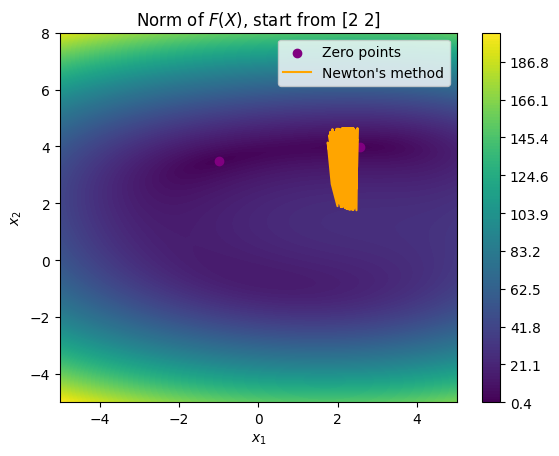

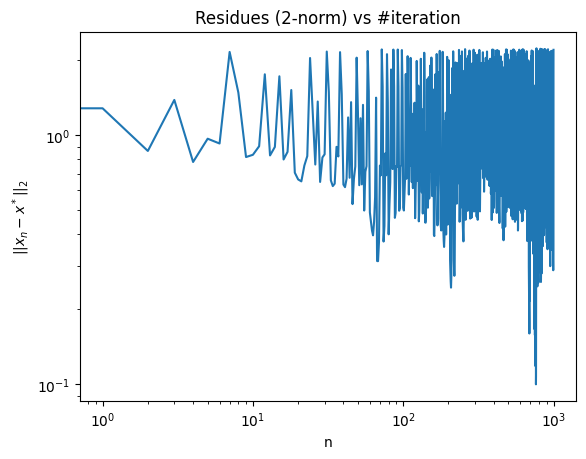

In [90]:
run(np.array([2, 2]), S1, "Q5.fixed2")

Initial value: [2 2]
Results: [-0.99997633  3.5000078 ]
Iteration: 569


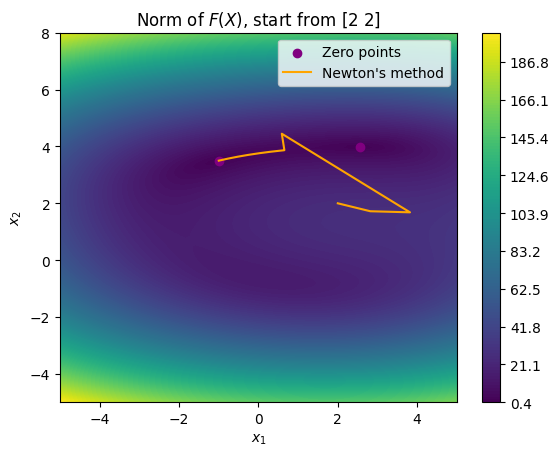

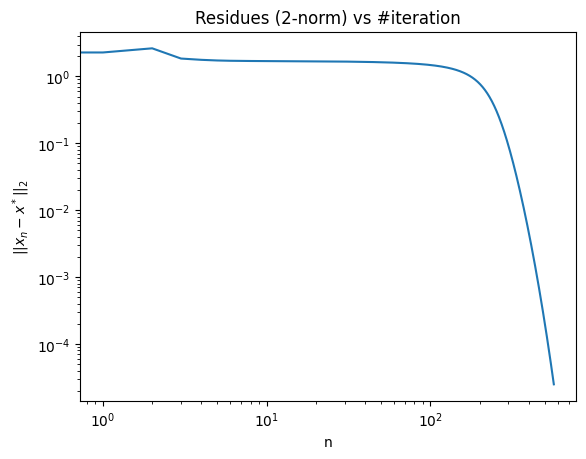

In [94]:
run(np.array([2, 2]), S2, "Q5.dynamic2")